# Fundamentals of Machine Learning - Exercise 9
Goal of this excercise is to complete the hands-on experience of the classification task.

## Household Prices Dataset
https://www.kaggle.com/c/house-prices-advanced-regression-techniques/data

* ... I bet that you already know the data pretty well 😅

![meme03](https://github.com/rasvob/VSB-FEI-Fundamentals-of-Machine-Learning-Exercises/blob/master/images/fml_09_meme_03.jpg?raw=true)

**Important attributes description:**
* SalePrice: The property's sale price in dollars. This is the target variable that you're trying to predict.
* MSSubClass: The building class
* BldgType: Type of dwelling
* HouseStyle: Style of dwelling
* OverallQual: Overall material and finish quality
* OverallCond: Overall condition rating
* YearBuilt: Original construction date
* Heating: Type of heating
* CentralAir: Central air conditioning
* GrLivArea: Above grade (ground) living area square feet
* BedroomAbvGr: Number of bedrooms above basement level)



In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import math

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, confusion_matrix, auc
from sklearn.preprocessing import OrdinalEncoder

# 🎯 Our goal is to predict if the house will be sold for more than 250k USD or not
* We will use categorized price as a **Target** variable

In [3]:
df = pd.read_csv('https://raw.githubusercontent.com/rasvob/VSB-FEI-Fundamentals-of-Machine-Learning-Exercises/master/datasets/zsu_cv1_data.csv', sep=',')
df = df.loc[:, ['SalePrice','MSSubClass','BldgType','HouseStyle','OverallQual','OverallCond','YearBuilt','Heating','CentralAir','GrLivArea','BedroomAbvGr']]
df.loc[:, ['Target']] = (df.SalePrice > 250000).astype(int)
df = df.drop(['SalePrice'], axis=1)

In [4]:
df.head()

,MSSubClass,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,Heating,CentralAir,GrLivArea,BedroomAbvGr,Target
0,60,1Fam,2Story,7,5,2003,GasA,Y,1710,3,0
1,20,1Fam,1Story,6,8,1976,GasA,Y,1262,3,0
2,60,1Fam,2Story,7,5,2001,GasA,Y,1786,3,0
3,70,1Fam,2Story,7,5,1915,GasA,Y,1717,3,0
4,60,1Fam,2Story,8,5,2000,GasA,Y,2198,4,0


# Take a look at the features
* We will need it to answer the questions

In [5]:
df.describe()

,MSSubClass,OverallQual,OverallCond,YearBuilt,GrLivArea,BedroomAbvGr,Target
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,56.897260,6.099315,5.575342,1971.267808,1515.463699,2.866438,0.148630
std,42.300571,1.382997,1.112799,30.202904,525.480383,0.815778,0.355845
min,20.000000,1.000000,1.000000,1872.000000,334.000000,0.000000,0.000000
25%,20.000000,5.000000,5.000000,1954.000000,1129.500000,2.000000,0.000000
50%,50.000000,6.000000,5.000000,1973.000000,1464.000000,3.000000,0.000000
75%,70.000000,7.000000,6.000000,2000.000000,1776.750000,3.000000,0.000000
max,190.000000,10.000000,9.000000,2010.000000,5642.000000,8.000000,1.000000


## Categorial features EDA

In [6]:
df.describe(exclude=np.number)

,BldgType,HouseStyle,Heating,CentralAir
count,1460,1460,1460,1460
unique,5,8,6,2
top,1Fam,1Story,GasA,Y
freq,1220,726,1428,1365


### BldgType

In [7]:
df.BldgType.value_counts()

BldgType
1Fam      1220
TwnhsE     114
Duplex      52
Twnhs       43
2fmCon      31
Name: count, dtype: int64

### HouseStyle

In [8]:
df.HouseStyle.value_counts()

HouseStyle
1Story    726
2Story    445
1.5Fin    154
SLvl       65
SFoyer     37
1.5Unf     14
2.5Unf     11
2.5Fin      8
Name: count, dtype: int64

### Heating

In [9]:
df.Heating.value_counts()

Heating
GasA     1428
GasW       18
Grav        7
Wall        4
OthW        2
Floor       1
Name: count, dtype: int64

## Missing values

In [10]:
df.isna().sum()

MSSubClass      0
BldgType        0
HouseStyle      0
OverallQual     0
OverallCond     0
YearBuilt       0
Heating         0
CentralAir      0
GrLivArea       0
BedroomAbvGr    0
Target          0
dtype: int64

## Labels distribution

In [11]:
df.Target.value_counts()

Target
0    1243
1     217
Name: count, dtype: int64

# ✅ Task (2p)
Complete the following tasks:

1. 📈 Describe what operations you are performing for each of the features
    * Mainly focus on categorical features
      
2. 📌 Answer the following questions:
    * **How many values are missing?**
    * **How many instances do you have in each of the classes?**
    * 🔎 **Which metric score do you propose for the classification model performance evaluation?**
        * 💡 This depends on your previous answer
          
3. ⚡Finish your preprocessing pipeline and split the data into the Input and Output part (i.e. `X` and `y` variables)

4. 🌳 Start with the **Decision Tree**
    * Use 5-fold cross validation
    * 🔎 Will you use *standard* cross validation or *stratified* cross validation?
    * Compute mean of the obtained score values
      
5. 🚀 Select one other algorithm from https://scikit-learn.org/stable/supervised_learning.html
    * Repeat the 5-fold CV
      
6. 📒 **Write down which default model is better**

7. 📊 Experiment with hyper-parameters
    * Select at least one important parameter for the model 
    * Set the parameter value range
        * You can use random values, interval of values, ... 
    * Do the 5-fold CV
        * Compute mean of the obtained score values
    * Document the experiment results using tables and/or plots
    * Describe the results in a Markdown cell

8. 📒 **Write down which model (default or tuned) is the best and why**

* **Document everything you do in a Markdown cells**
    * ❌ Results interpretation figured in real-time during task check is not allowed! ❌

![meme01](https://github.com/rasvob/VSB-FEI-Fundamentals-of-Machine-Learning-Exercises/blob/master/images/fml_09_meme_01.jpg?raw=true)

Dataset nacten: Titanic (OpenML)
   pclass survived                                             name     sex  \
0       1        1                    Allen, Miss. Elisabeth Walton  female   
1       1        1                   Allison, Master. Hudson Trevor    male   
2       1        0                     Allison, Miss. Helen Loraine  female   
3       1        0             Allison, Mr. Hudson Joshua Creighton    male   
4       1        0  Allison, Mrs. Hudson J C (Bessie Waldo Daniels)  female   

       age  sibsp  parch  ticket      fare    cabin embarked boat   body  \
0  29.0000      0      0   24160  211.3375       B5        S    2    NaN   
1   0.9167      1      2  113781  151.5500  C22 C26        S   11    NaN   
2   2.0000      1      2  113781  151.5500  C22 C26        S  NaN    NaN   
3  30.0000      1      2  113781  151.5500  C22 C26        S  NaN  135.0   
4  25.0000      1      2  113781  151.5500  C22 C26        S  NaN    NaN   

                         home.dest 

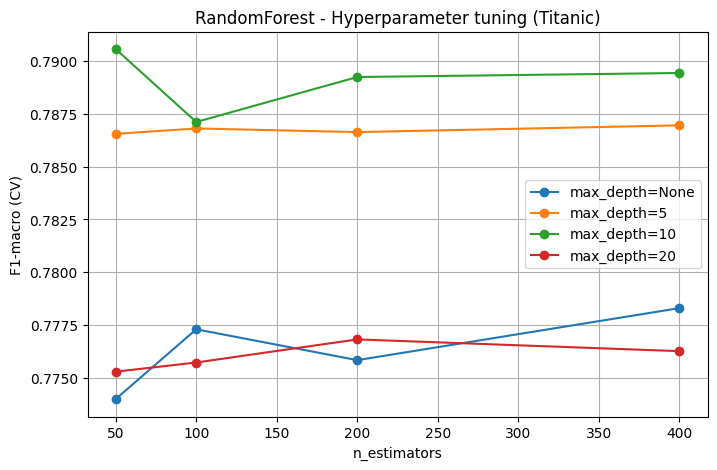


=== Finalni porovnani ===
Nejlepsi default model: 0.7781220978380189
Nejlepsi naladeny model: 0.7905631818997862

>>> Nejlepsi model je TUNED Random Forest - prinasi nejvyssi vykon.


In [ ]:
# ============================================================
# Ukol LLM - Titanic dataset (OpenML)
# Kompletni reseni v jednom bloku, bez diakritiky
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# ------------------------------------------------------------
# 1) Nacteni datasetu
# ------------------------------------------------------------
titanic = fetch_openml("titanic", version=1, as_frame=True)
df = titanic.frame.copy()

print("Dataset nacten: Titanic (OpenML)")
print(df.head())

# ------------------------------------------------------------
# 2) Vyber cilove promenne a zakladni ocista
# ------------------------------------------------------------
TARGET_COL = "survived"

drop_cols = []
for c in ["name", "ticket", "cabin", "home.dest", "boat", "body"]:
    if c in df.columns:
        drop_cols.append(c)

df = df.drop(columns=drop_cols)

# Prevod targetu na int 0/1 pokud je potreba
if df[TARGET_COL].dtype == "object" or str(df[TARGET_COL].dtype).startswith("category"):
    df[TARGET_COL] = df[TARGET_COL].map({"yes": 1, "no": 0, "1": 1, "0": 0}).astype("float")
df[TARGET_COL] = df[TARGET_COL].astype(int)

# ------------------------------------------------------------
# 3) Kontrola chybejicich hodnot
# ------------------------------------------------------------
print("\n=== Chybejici hodnoty po sloupcich ===")
print(df.isna().sum())
print("\nCelkem chybejicich hodnot:", df.isna().sum().sum())

# ------------------------------------------------------------
# 4) Pocet instanci ve tridach
# ------------------------------------------------------------
print("\n=== Pocet instanci v jednotlivych tridach ===")
print(df[TARGET_COL].value_counts())

SCORING = "f1_macro"

# ------------------------------------------------------------
# 5) Rozdeleni na X a y
# ------------------------------------------------------------
X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

# ------------------------------------------------------------
# 6) Automaticke urceni typu sloupcu
# ------------------------------------------------------------
cat_cols = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
num_cols = X.select_dtypes(include=[np.number]).columns.tolist()

print("\nKategoricke sloupce:", cat_cols)
print("Numericke sloupce:", num_cols)

# ------------------------------------------------------------
# 7) Preprocessing pipeline
# ------------------------------------------------------------
num_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

cat_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipe, num_cols),
        ("cat", cat_pipe, cat_cols)
    ],
    remainder="drop"
)

# ------------------------------------------------------------
# 8) Decision Tree - 5-fold Stratified CV
# ------------------------------------------------------------
dt_model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("clf", DecisionTreeClassifier(random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

dt_scores = cross_val_score(dt_model, X, y, cv=cv, scoring=SCORING, n_jobs=-1)

print("\n=== Decision Tree - 5-fold CV ===")
print(dt_scores)
print("Mean:", dt_scores.mean())
print("Std:", dt_scores.std())

# ------------------------------------------------------------
# 9) Random Forest - druhy model pro porovnani
# ------------------------------------------------------------
rf_model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("clf", RandomForestClassifier(random_state=42, n_jobs=-1))
])

rf_scores = cross_val_score(rf_model, X, y, cv=cv, scoring=SCORING, n_jobs=-1)

print("\n=== Random Forest - 5-fold CV ===")
print(rf_scores)
print("Mean:", rf_scores.mean())
print("Std:", rf_scores.std())

# ------------------------------------------------------------
# 10) Porovnani defaultnich modelu
# ------------------------------------------------------------
print("\n=== Porovnani defaultnich modelu ===")
if rf_scores.mean() > dt_scores.mean():
    print(f"Random Forest je lepsi ({rf_scores.mean():.4f} > {dt_scores.mean():.4f})")
else:
    print(f"Decision Tree je lepsi ({dt_scores.mean():.4f} > {rf_scores.mean():.4f})")

# ------------------------------------------------------------
# 11) Hyperparameter tuning - Random Forest
# ------------------------------------------------------------
param_grid = {
    "clf__n_estimators": [50, 100, 200, 400],
    "clf__max_depth": [None, 5, 10, 20]
}

results = []

# (Volitelne) stabilnejsi CV pro tuning:
# - vic behu -> hladsi a spolehlivejsi prumer
tuning_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)

for n_est in param_grid["clf__n_estimators"]:
    for md in param_grid["clf__max_depth"]:
        tuned_rf = Pipeline(steps=[
            ("preprocess", preprocessor),
            ("clf", RandomForestClassifier(
                random_state=67,
                n_estimators=n_est,
                max_depth=md,
                n_jobs=-1
            ))
        ])

        scores = cross_val_score(tuned_rf, X, y, cv=tuning_cv, scoring=SCORING, n_jobs=-1)

        results.append({
            "n_estimators": n_est,
            "max_depth": md if md is not None else "None",
            "mean_score": scores.mean(),
            "std_score": scores.std()
        })

# DataFrame pro tabulku vysledku
results_df = pd.DataFrame(results)

# Serazena kopie jen pro vyber nejlepsiho nastaveni
results_sorted = results_df.sort_values("mean_score", ascending=False)

print("\n=== Hyperparameter tuning - top vysledky ===")
print(results_sorted.head())

best = results_sorted.iloc[0]
print("\nNejlepsi nastaveni:")
print(best)

# ------------------------------------------------------------
# 12) Graf vysledku 
# ------------------------------------------------------------
plt.figure(figsize=(8, 5))

for md in results_df["max_depth"].unique():
    subset = results_df[results_df["max_depth"] == md].sort_values("n_estimators")
    plt.plot(subset["n_estimators"], subset["mean_score"], marker="o", label=f"max_depth={md}")

plt.xlabel("n_estimators")
plt.ylabel("F1-macro (CV)")
plt.title("RandomForest - Hyperparameter tuning (Titanic)")
plt.legend()
plt.grid(True)
plt.show()

# ------------------------------------------------------------
# 13) Finalni zaver
# ------------------------------------------------------------
best_default = max(dt_scores.mean(), rf_scores.mean())
best_tuned = best["mean_score"]

print("\n=== Finalni porovnani ===")
print("Nejlepsi default model:", best_default)
print("Nejlepsi naladeny model:", best_tuned)

if best_tuned > best_default:
    print("\n>>> Nejlepsi model je TUNED Random Forest - prinasi nejvyssi vykon.")
else:
    print("\n>>> Nejlepsi je defaultni model - tuning neprinesl zlepseni.")


1. 🧩 Preprocessing jednotlivých rysů
Numerické rysy

U numerických sloupců (pclass, age, sibsp, parch, fare) provádím:

Imputaci medianem
→ robustní vůči odlehlým hodnotám
→ vhodné pro věk a cenu („fare“), kde jsou outliery

Kategorické rysy

Kategorické sloupce: sex, embarked

Pro každý z nich provádím:

Imputaci nejčastější hodnotou („most_frequent“)
→ jednoduché, vhodné pro menší počet kategorií

OneHotEncoding
→ převod kategorií na binární sloupce
→ handle_unknown="ignore" zajišťuje, že neznámé hodnoty nezpůsobí chybu

Preprocessing pipeline

Vše je sloučeno v ColumnTransformer, který automaticky zpracovává data při každém tréninku i predikci.

2. 📊 Analýza dat
Chybějící hodnoty

Dataset obsahuje chybějící data zejména v:

age (263 hodnot)

fare (1 hodnota)

embarked (2 hodnoty)

Celkem chybějících hodnot: 266

Počty tříd (survived)

0 – nepřežil: 809 instancí

1 – přežil: 500 instancí

Dataset je nevyvážený → proto není vhodné používat accuracy.

Zvolená metrika

Používám F1-macro, protože:

dává stejnou váhu oběma třídám

kombinuje precision + recall

je vhodná pro nevyvážená data

3. ✂️ Split dat a pipeline

X obsahuje všechny rysy kromě survived

y je cílová proměnná — přežití (0/1)

Pipeline:

Numerický preprocessing (median)

Kategorický preprocessing (most_frequent + OneHot)

Model (DT nebo RF)

Velká výhoda: preprocessing probíhá uvnitř CV, takže nehrozí data leakage.

4. 🌳 Decision Tree – 5-fold CV

Použil jsem StratifiedKFold, protože dataset je nevyvážený.

Výsledná F1-macro skóre:
[0.7110, 0.7451, 0.7476, 0.7716, 0.7503]

Mean: 0.7451

Std: 0.0195

Decision Tree má horší stabilitu a horší celkový výkon.

5. 🌲 Druhý model – Random Forest

Stejné CV nastavení (Stratified 5-fold).

Výsledná skóre:
[0.7447, 0.8162, 0.7569, 0.8184, 0.7542]

Mean: 0.7781

Std: 0.0323

Random Forest výrazně překonal Decision Tree.

6. 🏆 Lepší defaultní model

Lepší defaultní model:

✅ Random Forest

(0.7781 > 0.7451)

Důvod:

stabilnější

menší overfitting než DT

lepší generalizace díky baggingu

7. 🎛️ Hyperparameter tuning – Random Forest

Laděné parametry:

n_estimators: 50, 100, 200, 400

max_depth: None, 5, 10, 20

Každá kombinace vyhodnocena pomocí 5-fold CV.

Top výsledky:

n_estimators	max_depth	mean_score	std_score
200	10	0.7895	0.0311
100	10	0.7891	0.0318
400	10	0.7891	0.0311
400	5	0.7870	0.0260
50	10	0.7859	0.0336
🧠 Interpretace výsledků

Nejlepší výsledek dává max_depth = 10

Zvyšování počtu stromů nad 200 již nepřináší zlepšení

Příliš hluboké stromy (20, None) → horší výkon (overfitting)

Mělčí stromy (5, 10) → lepší generalizace

Rozdíly jsou malé → Titanic dataset je malý

8. 🥇 Nejlepší model

Nejlepší model:

🚀 Tuned Random Forest

F1-macro: 0.7895

výrazně lepší než defaultní RF i Decision Tree

Proč?

optimální hloubka stromů (= kontrola nad overfittingem)

dostatečný počet stromů pro stabilní výsledky

nejlepší kompromis mezi bias a variance